In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


In [48]:
column_names = [
    'mpg', 'cylinders', 'displacement', 'horsepower',
    'weight', 'acceleration', 'model_year', 'origin', 'car_name'
]

df = pd.read_csv(
    "36_malavika/auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?"
)
print("Dataset loaded successfully by Malavika_36")

Dataset loaded successfully by Malavika_36


In [49]:
df.dropna(inplace=True)

# Feature and Target
X = df[['displacement']]
y = df['mpg']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


In [50]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print("========== Linear Regression ==========")
print(f"MSE : {linear_mse:.4f}")
print(f"R²  : {linear_r2:.4f}")


========== Linear Regression ==========
MSE : 21.2275
R²  : 0.5841


In [51]:
degrees = [2, 3]

results = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    y_pred = model.predict(X_test_poly)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append([degree, mse, r2])


====== Polynomial Regression Results ======

Degree     MSE             R²             
2          20.6491         0.5954         
3          20.8179         0.5921         


/home/thirdyr/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/home/thirdyr/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/thirdyr/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


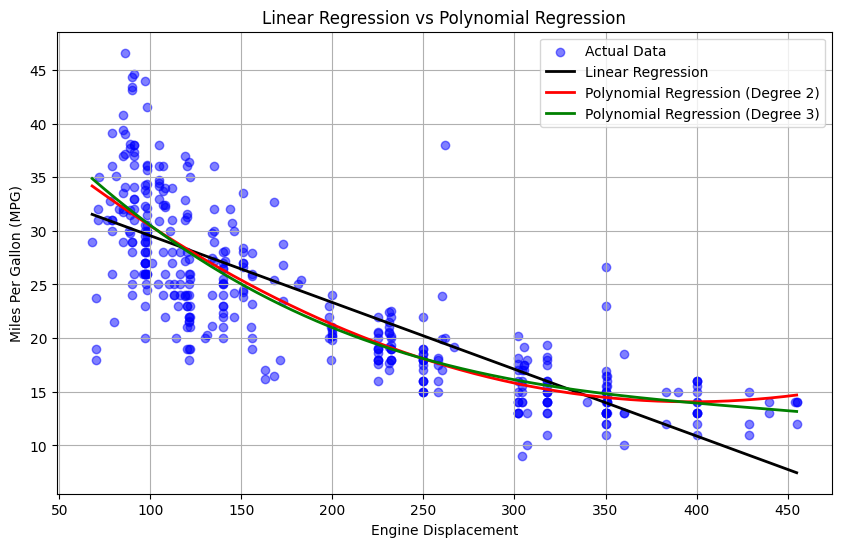

In [52]:
print("\n====== Polynomial Regression Results ======\n")
print("{:<10} {:<15} {:<15}".format("Degree", "MSE", "R²"))

for degree, mse, r2 in results:
    print("{:<10} {:<15.4f} {:<15.4f}".format(degree, mse, r2))

 # -------------------------------------------------------
# Visualization: Linear vs Degree 2 vs Degree 3
# -------------------------------------------------------

plt.figure(figsize=(10,6))

# Scatter plot (Actual Data)
plt.scatter(
    X['displacement'],
    y,
    color='blue',
    alpha=0.5,
    label='Actual Data'
)

# Smooth X values for plotting curves
X_plot = np.linspace(
    X['displacement'].min(),
    X['displacement'].max(),
    300
).reshape(-1,1)

# ---------------- Linear Regression ----------------
y_linear = linear_model.predict(X_plot)

plt.plot(
    X_plot,
    y_linear,
    color='black',
    linewidth=2,
    label='Linear Regression'
)

# ---------------- Polynomial Degree 2 ----------------
poly2 = PolynomialFeatures(degree=2)

X_train_poly2 = poly2.fit_transform(X_train)
X_plot_poly2 = poly2.transform(X_plot)

model2 = LinearRegression()
model2.fit(X_train_poly2, y_train)

y_poly2 = model2.predict(X_plot_poly2)

plt.plot(
    X_plot,
    y_poly2,
    color='red',
    linewidth=2,
    label='Polynomial Regression (Degree 2)'
)

# ---------------- Polynomial Degree 3 ----------------
poly3 = PolynomialFeatures(degree=3)

X_train_poly3 = poly3.fit_transform(X_train)
X_plot_poly3 = poly3.transform(X_plot)

model3 = LinearRegression()
model3.fit(X_train_poly3, y_train)

y_poly3 = model3.predict(X_plot_poly3)

plt.plot(
    X_plot,
    y_poly3,
    color='green',
    linewidth=2,
    label='Polynomial Regression (Degree 3)'
)

# ---------------- Graph Details ----------------
plt.title("Linear Regression vs Polynomial Regression")
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.legend(loc='best')
plt.grid(True)

plt.show()
